# (a) Validation: predicted vs measured throughput and energy

This notebook compares `perfmodel` predictions with measurements from
`bench/bench_decode.py`. It reads the CSV named by the `PERFMODEL_BENCH_CSV`
environment variable and falls back to `bench/results/sample_synthetic.csv`.

> **About the sample file.** `sample_synthetic.csv` is **not** a measurement.
> It is the model's own prediction distorted with planted parameters
> (bandwidth and compute efficiency, per-kernel overhead, static power, noise;
> see `bench/make_sample_data.py`). On that file, the calibration below
> recovers the planted values *by construction*, so the fit quality is
> circular and validates nothing. It is here so the plots and statistics work
> before real GPU data exists.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "notebooks"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotstyle as ps
from perfmodel import load_model, load_chip, predict_step
ps.apply()
pd.set_option("display.precision", 3)

In [2]:
csv = Path(os.environ.get("PERFMODEL_BENCH_CSV", ROOT / "bench/results/sample_synthetic.csv"))
if not csv.is_absolute():
    csv = ROOT / csv
meas = pd.read_csv(csv)
SYNTHETIC = bool(meas.get("synthetic", pd.Series([0])).astype(int).any())
print(f"{csv.name}: {len(meas)} rows, GPUs: {meas.gpu_name.unique().tolist()}")
if SYNTHETIC:
    print("WARNING: SYNTHETIC data. Error statistics below are NOT a validation result.")
meas.head()

sample_synthetic.csv: 50 rows, GPUs: ['SYNTHETIC (A100-SXM4-80GB-like)']


,timestamp,gpu_name,gpu_mem_gib,model_id,perfmodel_model,perfmodel_chip,dtype,attn_impl,synthetic,idle_power_w,...,batch,context,n_steps,step_ms_median,tokens_per_s,avg_power_w,energy_per_token_j,energy_method,energy_reliable,fixed_context
0,synthetic,SYNTHETIC (A100-SXM4-80GB-like),80,Qwen/Qwen2.5-1.5B,qwen2.5-1.5b,a100,bfloat16,sdpa,1,60.0,...,1,128,100,8.159,122.565,90.314,0.737,synthetic,True,True
1,synthetic,SYNTHETIC (A100-SXM4-80GB-like),80,Qwen/Qwen2.5-1.5B,qwen2.5-1.5b,a100,bfloat16,sdpa,1,60.0,...,1,512,100,8.082,123.732,90.725,0.733,synthetic,True,True
2,synthetic,SYNTHETIC (A100-SXM4-80GB-like),80,Qwen/Qwen2.5-1.5B,qwen2.5-1.5b,a100,bfloat16,sdpa,1,60.0,...,1,1024,100,8.345,119.833,89.914,0.750,synthetic,True,True
3,synthetic,SYNTHETIC (A100-SXM4-80GB-like),80,Qwen/Qwen2.5-1.5B,qwen2.5-1.5b,a100,bfloat16,sdpa,1,60.0,...,1,2048,100,8.186,122.155,90.815,0.743,synthetic,True,True
4,synthetic,SYNTHETIC (A100-SXM4-80GB-like),80,Qwen/Qwen2.5-1.5B,qwen2.5-1.5b,a100,bfloat16,sdpa,1,60.0,...,1,4096,100,8.015,124.770,92.131,0.738,synthetic,True,True


## Predictions for every measured point

Each measured row maps to one model step:
* decode at context `C` = one new token on top of `C` cached tokens (the bench
  crops the cache so the context stays fixed);
* prefill of `C` tokens = `n_past = 0`, `n_new = C`.

The **pure** prediction is the roofline with 100% efficiency and no overhead.

In [3]:
def predict_row(r, **kw):
    m, c = load_model(r.perfmodel_model), load_chip(r.perfmodel_chip)
    n_past, n_new = (int(round(r.context)), 1) if r.phase == "decode" else (0, int(r.context))
    return predict_step(m, c, int(r.batch), n_past, n_new, **kw)

preds = [predict_row(r) for r in meas.itertuples()]
df = meas.copy()
df["t_meas"] = df.step_ms_median / 1e3
df["t_pred"] = [p.time_s for p in preds]
df["tps_pred"] = [p.tokens_per_s for p in preds]
df["n_kernels"] = [p.n_kernels for p in preds]
df["e_dyn_pred"] = [p.energy_j for p in preds]                  # J per step, dynamic only
df["e_meas"] = df.energy_per_token_j * df.batch * np.where(df.phase == "decode", 1, df.context)
df["ratio"] = df.tokens_per_s / df.tps_pred                      # < 1: slower than predicted

def err_stats(pred, true):
    ape = np.abs(pred - true) / true
    return pd.Series({"MAPE_%": 100 * ape.mean(), "median_APE_%": 100 * np.median(ape),
                      "max_APE_%": 100 * ape.max(), "within_20%": (ape <= 0.2).mean()})

pure = df.groupby("phase").apply(lambda g: err_stats(g.tps_pred, g.tokens_per_s),
                                 include_groups=False)
pure

,MAPE_%,median_APE_%,max_APE_%,within_20%
phase,,,,
decode,347.224,376.360,459.017,0.0
prefill,138.078,100.334,348.188,0.0


## Calibrated model: two physically meaningful parameters

A pure roofline is a lower bound on time. Real kernels reach only part of peak
bandwidth, and every kernel launch pays a fixed cost. For Hugging Face eager
mode that cost is mostly Python and CPU dispatch. Model it as

$$ t_\text{meas} \approx \alpha \, t_\text{roofline} + \beta \, n_\text{kernels} $$

where $1/\alpha$ is the achieved fraction of the roofline and $\beta$ is the
overhead per kernel. Fit on **decode rows with context ≤ 1024** and test on
the **longer contexts**. The held-out rows check whether the calibration
extrapolates or just memorizes.

In [4]:
dec = df[df.phase == "decode"].copy()
train = dec[dec.context <= 1024]
test = dec[dec.context > 1024]
X = np.c_[train.t_pred, train.n_kernels]
(alpha, beta), *_ = np.linalg.lstsq(X, train.t_meas, rcond=None)
print(f"alpha = {alpha:.3f}  (-> {100/alpha:.0f}% of roofline)   beta = {beta*1e6:.1f} us/kernel")

for d in (df,):
    d["t_cal"] = alpha * d.t_pred + beta * d.n_kernels
    d["tps_cal"] = d.tps_pred * d.t_pred / d.t_cal
dec = df[df.phase == "decode"]
pd.DataFrame({
    "pure, all decode": err_stats(dec.tps_pred, dec.tokens_per_s),
    "calibrated, train (C<=1024)": err_stats(dec[dec.context <= 1024].tps_cal,
                                             dec[dec.context <= 1024].tokens_per_s),
    "calibrated, HELD-OUT (C>1024)": err_stats(dec[dec.context > 1024].tps_cal,
                                               dec[dec.context > 1024].tokens_per_s),
}).T

alpha = 1.202  (-> 83% of roofline)   beta = 20.1 us/kernel


,MAPE_%,median_APE_%,max_APE_%,within_20%
"pure, all decode",347.224,376.360,459.017,0.0
"calibrated, train (C<=1024)",2.308,1.966,8.461,1.0
"calibrated, HELD-OUT (C>1024)",3.228,2.506,9.001,1.0


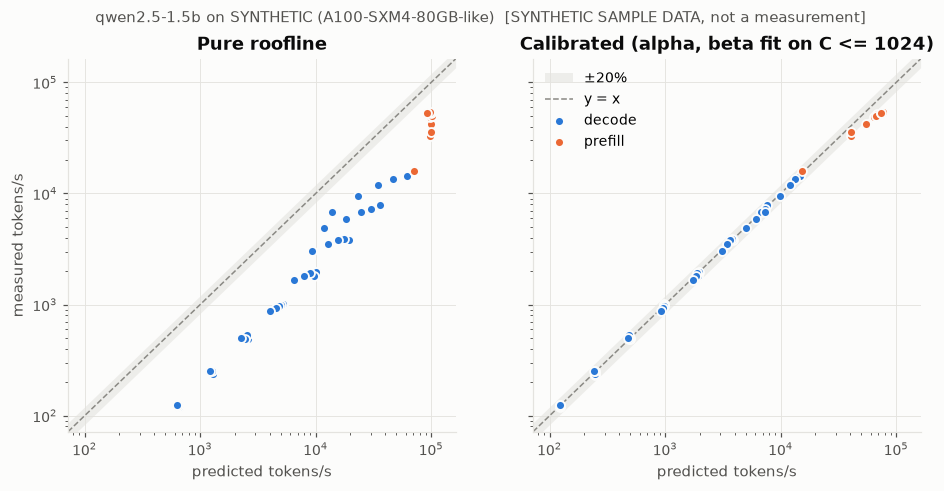

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharex=True, sharey=True)
lo = min(df.tokens_per_s.min(), df.tps_pred.min(), df.tps_cal.min()) * 0.6
hi = max(df.tokens_per_s.max(), df.tps_pred.max(), df.tps_cal.max()) * 1.6
for ax, col, title in [(axes[0], "tps_pred", "Pure roofline"),
                       (axes[1], "tps_cal", "Calibrated (alpha, beta fit on C <= 1024)")]:
    xs = np.array([lo, hi])
    ax.fill_between(xs, xs / 1.2, xs * 1.2, color=ps.GRID, alpha=0.6, lw=0, label="±20%")
    ax.plot(xs, xs, color=ps.NEUTRAL, lw=1, ls="--", label="y = x")
    for i, ph in enumerate(["decode", "prefill"]):
        g = df[df.phase == ph]
        ax.scatter(g[col], g.tokens_per_s, s=34, color=ps.SERIES[i], label=ph,
                   edgecolor=ps.SURFACE, linewidth=1.2, zorder=3)
    ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi), title=title,
           xlabel="predicted tokens/s")
axes[0].set_ylabel("measured tokens/s")
axes[1].legend(loc="upper left")
tag = "  [SYNTHETIC SAMPLE DATA, not a measurement]" if SYNTHETIC else ""
fig.suptitle(f"{df.perfmodel_model.iloc[0]} on {df.gpu_name.iloc[0]}{tag}", fontsize=10,
             color=ps.INK_2)
ps.save(fig, "validation_tokens_per_s");

### Where the error lives: measured / predicted vs batch

A ratio of 1 means the pure roofline is exact. Values far below 1 at small
batch mean fixed overhead dominates, not memory or compute.

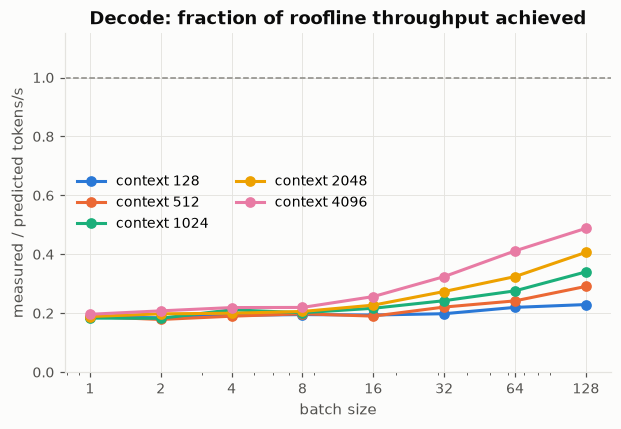

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 4))
for i, (c, g) in enumerate(dec.groupby("context")):
    g = g.sort_values("batch")
    ax.plot(g.batch, g.ratio, marker="o", color=ps.SERIES[i], label=f"context {int(c)}")
ax.axhline(1, color=ps.NEUTRAL, lw=1, ls="--")
ax.set(xscale="log", xlabel="batch size", ylabel="measured / predicted tokens/s",
       title="Decode: fraction of roofline throughput achieved", ylim=(0, 1.15))
ax.set_xticks(sorted(dec.batch.unique()), [str(int(b)) for b in sorted(dec.batch.unique())])
ax.legend(title=None, ncols=2)
ps.save(fig, "validation_ratio_vs_batch");

## Energy per token

The energy model predicts only **dynamic** energy, using Horowitz 45 nm
constants. Measured board energy also includes static and idle power and
everything the model leaves out (control, caches, interconnect, VRMs), and
the GPU is built in a much newer process. Fit

$$ E_\text{meas} \approx k \, E_\text{dyn} + P_\text{static} \, t_\text{meas} $$

on decode rows, then compare $P_\text{static}$ with the idle power the bench
measured.

In [7]:
ok = dec[dec.energy_reliable.astype(bool) & dec.e_meas.notna()]
(k, p_static), *_ = np.linalg.lstsq(np.c_[ok.e_dyn_pred, ok.t_meas], ok.e_meas, rcond=None)
print(f"k = {k:.2f}x Horowitz dynamic energy,  P_static = {p_static:.1f} W  "
      f"(bench idle power: {ok.idle_power_w.iloc[0]:.1f} W)")
df["ept_dyn"] = df.e_dyn_pred / (df.batch * np.where(df.phase == "decode", 1, df.context))
df["ept_cal"] = (k * df.e_dyn_pred + p_static * df.t_meas) / (
    df.batch * np.where(df.phase == "decode", 1, df.context))
d = df[df.phase == "decode"]
pd.DataFrame({"dynamic only": err_stats(d.ept_dyn, d.energy_per_token_j),
              "k*E_dyn + P_static*t": err_stats(d.ept_cal, d.energy_per_token_j)}).T

k = 2.50x Horowitz dynamic energy,  P_static = 60.0 W  (bench idle power: 60.0 W)


,MAPE_%,median_APE_%,max_APE_%,within_20%
dynamic only,8.171e+01,8.372e+01,8.671e+01,0.0
k*E_dyn + P_static*t,3.597e-14,3.517e-14,5.466e-14,1.0


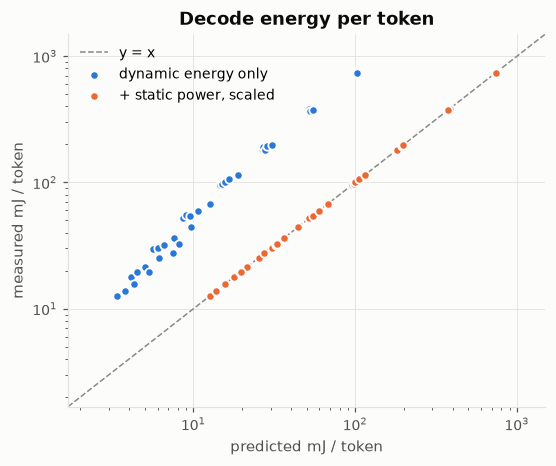

In [8]:
fig, ax = plt.subplots(figsize=(5.6, 4.4))
cols = ["ept_dyn", "ept_cal", "energy_per_token_j"]
lo, hi = d[cols].min().min() * 1e3 * 0.5, d[cols].max().max() * 1e3 * 2  # mJ
ax.plot([lo, hi], [lo, hi], color=ps.NEUTRAL, ls="--", lw=1, label="y = x")
ax.scatter(d.ept_dyn * 1e3, d.energy_per_token_j * 1e3, color=ps.SERIES[0], s=30,
           label="dynamic energy only", edgecolor=ps.SURFACE, lw=1.2, zorder=3)
ax.scatter(d.ept_cal * 1e3, d.energy_per_token_j * 1e3, color=ps.SERIES[1], s=30,
           label="+ static power, scaled", edgecolor=ps.SURFACE, lw=1.2, zorder=3)
ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi), xlabel="predicted mJ / token", ylabel="measured mJ / token",
       title="Decode energy per token")
ax.legend(loc="upper left")
ps.save(fig, "validation_energy");

## Where the model is wrong (and why)

These are the known failure modes, roughly ordered by how much they matter
for **Hugging Face eager decode of a 1-2B model**. Re-read them against the
real numbers above once measurements replace the sample file.

1. **Fixed per-kernel overhead dominates small-batch decode.** The 1.5B model
   moves about 3 GB per step, which takes about 1.5 ms at 2 TB/s. HF eager
   launches ~300+ kernels per token, each with Python dispatch cost, so
   measured tokens/s at batch 1 can be several times below the roofline.
   This is a software property, not a hardware one. CUDA graphs,
   `torch.compile` or a serving engine (vLLM, TensorRT-LLM) remove most of it.
   The roofline is the right target *for those stacks*.
2. **Peak bandwidth isn't reachable.** Streaming kernels typically reach
   80-90% of HBM peak, and small GEMVs (narrow matrices) reach less. A single
   global $\alpha$ hides the fact that efficiency varies per op.
3. **HF's `DynamicCache` copies the KV cache on every step** (`torch.cat`),
   adding about 2x KV traffic that the model does not count. This error grows
   with context × batch.
4. **Attention kernels.** SDPA decode with one query token is a poorly
   utilized kernel, and the unfused path materializes scores. Try
   `--unfused-attention` in the CLI to bracket this.
5. **Compute efficiency in prefill.** Prefill is compute-bound, and real
   GEMMs reach 60-80% of tensor-core peak, so the pure model is optimistic.
6. **Caches help the model's pessimistic side.** On GPUs the model treats L2
   as absent. Small KV caches and activations do hit L2, so some memory-bound
   ops beat the DRAM roofline.
7. **Logits in fp32, sampling, and host syncs** (the `argmax` each step) are
   small costs that are not modeled.
8. **Energy.** Horowitz numbers are for 45 nm. A 7 nm A100 spends less per
   operation, yet board power includes static power, clocks, memory PHY and
   VRM losses that the model leaves out entirely. Expect large absolute errors
   (the fitted $k$ and $P_\text{static}$ quantify them). The *relative*
   ordering (DRAM bytes dominate decode energy) is the useful output.
   NVML power is averaged over ≥100 ms windows, so short runs are unreliable.
   The bench enforces ≥2 s timed regions and flags shorter ones.

**What should hold even on real data:** the *shape*. Throughput scales almost
linearly with batch until the weight matmuls cross the ridge point,
throughput falls with context once KV reads rival weight reads, and decode
energy per token falls with batch because weight reads are shared.